# 14 - NMR Petrophysics

**Part B - Petrophys Curriculum**

Nuclear Magnetic Resonance (NMR) logging measures the relaxation of hydrogen
protons in the pore fluid. Unlike density, neutron or sonic tools, the NMR
response is **independent of the rock matrix** - it "sees" only the fluids in
the pore space. That single property makes NMR the most direct downhole
measurement of porosity, pore-size distribution, bound versus movable fluid,
and (through empirical models) permeability.

This notebook works the `petrophys.nmr` toolkit on a **real CMR log**: the
Schlumberger CMR summary deliverable from **Daydream 1** (QGC, ATP 645, Bowen
Basin, Queensland) - the same publicly released well whose FMI drives
notebook 16. Two depth sections ship with the package; we use the deep one
(3755-4145 m) and leave the shallow one for the exercises.

## Learning goals

By the end of this notebook you will be able to:

- Load a real CMR summary deliverable into `NMRData` with `from_las`
  (mnemonic aliases, automatic v/v-to-pu conversion, `MBVI` derived as
  `MPHI - MFFI`).
- Read the porosity partition (bound vs free fluid) and **Swirr** from real
  curves, at the T2 cutoff recorded in the file itself.
- Compute **Timur-Coates permeability** from the summary curves and validate
  it against the vendor's own `KTIM`, recovering the vendor's constant with
  `calibrate_coates`.
- Know which products need **T2 bins** (T2 distribution, T2lm, SDR
  permeability, pore size) and how `NMRData` refuses rather than guesses when
  they are absent.

## Why this matters (the physics)

After a polarizing pulse, hydrogen protons in the pore fluid relax back to
equilibrium with a **transverse relaxation time $T_2$**. In a water-wet rock the
dominant mechanism is *surface relaxation*, and to first order

$$\frac{1}{T_2} \approx \rho_2\,\frac{S}{V},$$

where $\rho_2$ is the surface relaxivity and $S/V$ is the pore surface-to-volume
ratio. Small pores have a **large** $S/V$ and relax **fast** (short $T_2$); large
pores relax slowly (long $T_2$). So the measured **T2 distribution is a proxy for
the pore-size distribution**:

- **Short $T_2$** -> tiny/clay-bound and capillary-bound water -> **irreducible** (BVI).
- **Long $T_2$** -> large pores holding **movable** (free) fluid (FFI).

A single **T2 cutoff** separates the two. The total area under the T2
distribution is the **NMR porosity (MPHI)** - matrix-independent, hence a
gold-standard porosity.

### Prerequisites
This notebook assumes you have worked through the Part A porosity (04) and
permeability (08) notebooks. Basic familiarity with porosity units (fractions
vs porosity units, "pu" = percent) is helpful.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.nmr import NMRData

print("petrophys", petrophys.__version__)

petrophys 0.1.0


## 1. Load the real CMR deliverable

The bundled `daydream1_cmr.las` is the service company's standard CMR summary
export: total porosity `TCMR`, free fluid `CMFF`, 3-ms porosity `CMRP_3MS`,
the vendor's SDR and Timur permeabilities `KSDR` / `KTIM`, the `T2CUTOFF`
actually applied downhole, plus GR and calipers for QC.

`NMRData.from_las` does the housekeeping:

- resolves CMR mnemonics onto the MRIL-style names the container uses
  (`TCMR -> MPHI`, `CMFF -> MFFI`),
- converts fractional (v/v) porosities to **pu**,
- derives `MBVI = MPHI - MFFI` when no bound-fluid curve is present,
- reads the T2 cutoff from the `T2CUTOFF` curve,
- stores the vendor permeabilities and every remaining curve
  (`stored_permeability`, `extra_curves`).

One quirk of the file: it is written deepest-first (decreasing depth), which
the LAS reader flags with a warning. Per-sample NMR arithmetic is unaffected.

In [2]:
nmr = NMRData.from_las(
    petrophys.sample("daydream1_cmr"),
    mphi_mnemonic="TCMR", mffi_mnemonic="CMFF",
)

print("samples          :", nmr.n_samples)
print("depth            : %.1f - %.1f m" % (nmr.top, nmr.bottom))
print("T2 cutoff        : %.0f ms (from the T2CUTOFF curve)" % nmr.t2_cutoff)
print("has_bins / has_t2lm:", nmr.has_bins, "/", nmr.has_t2lm)
print("MPHI (pu)        : median %.2f, max %.1f" % (np.nanmedian(nmr.mphi), np.nanmax(nmr.mphi)))
print("vendor perms     :", sorted(nmr.stored_permeability))
print("extra curves     :", sorted(nmr.extra_curves))

samples          : 15606


depth            : 3755.0 - 4145.1 m
T2 cutoff        : 33 ms (from the T2CUTOFF curve)
has_bins / has_t2lm: False / False
MPHI (pu)        : median 6.63, max 72.2
vendor perms     : ['KSDR', 'KTIM']
extra curves     : ['BS', 'CDF', 'CMRP_3MS', 'CMR_TEMP', 'GR_EDTC', 'HD1_PPC1', 'HD2_PPC1', 'KSDR', 'KTIM', 'STIT', 'T2CUTOFF', 'TENS']


## 2. Summary curves vs T2 bins

This deliverable carries **summary curves only** - the per-depth T2 bin
amplitudes (the full T2 distribution) were never exported to LAS. That rules
out the bin-based products:

- the **T2 distribution** itself and its **log-mean T2lm**,
- **SDR permeability** ($k = C\,\phi^4\,T2_{lm}^2$), which needs T2lm,
- **pore-size** estimates from surface relaxivity,
- re-splitting BVI/FFI at a *different* cutoff (the vendor's split at 33 ms is
  baked into `CMFF`).

When bin data exist, `NMRData` ingests them via `from_csv` / `bin_mnemonics`
(MRIL `P1...P8` or `T2B01...T2B08`). We do not fabricate bins to demo those
methods - and the container is honest when asked for something the data cannot
support:

In [3]:
try:
    nmr.permeability_sdr(prefer_stored=False)
except ValueError as e:
    print("permeability_sdr(prefer_stored=False) raises:")
    print("  ValueError:", e)

# The vendor's KSDR - computed downhole from the full T2 distribution - is
# still available, because prefer_stored defaults to True:
ksdr = nmr.permeability_sdr()
print()
print("nmr.permeability_sdr() returns the stored vendor KSDR: median %.4f mD"
      % np.nanmedian(ksdr))

permeability_sdr(prefer_stored=False) raises:
  ValueError: T2lm requires either T2 bin data (P1–P8) or a T2LM curve loaded from the LAS file (pass t2lm_mnemonic='T2LM' to from_las).

nmr.permeability_sdr() returns the stored vendor KSDR: median 0.0009 mD


## 3. Porosity partition and Swirr

The deep section sits in tight Permian coal measures, and the real curves say
so: the median total NMR porosity is only ~6.6 pu, and nearly all of it is
**bound fluid** (median `CMFF` is ~0.5 pu). The NMR irreducible saturation
$S_{wirr} = MBVI/MPHI$ is therefore very high across the section.

MPHI  (pu): median 6.63
MFFI  (pu): median 0.49
MBVI  (pu): median 6.01  (derived MPHI - MFFI)
Swirr     : median 0.92


petrophys\io\las_reader.py:381: UserWarning: Depth index issue in petrophys\data\daydream\daydream1_cmr.las: depth is decreasing (reversed). Downstream thickness/net-pay/zone calculations assume increasing depth.
  return reader.to_well()


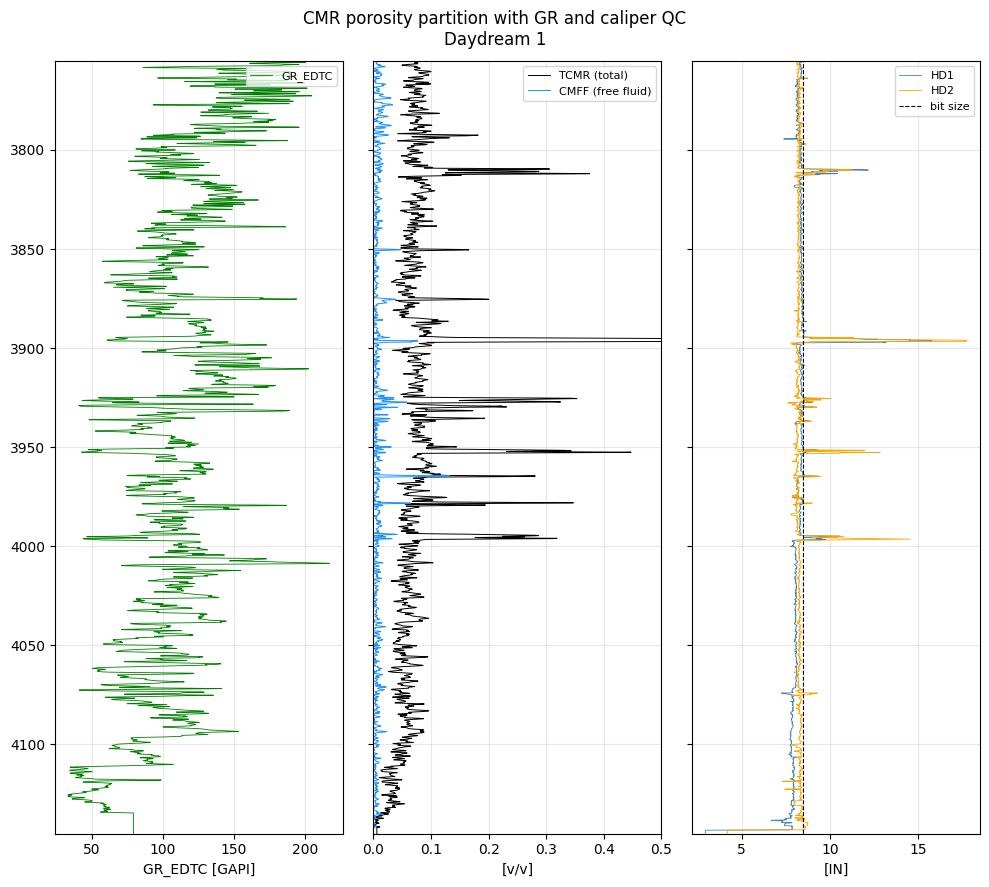

In [4]:
swirr = nmr.swirr_nmr()
print("MPHI  (pu): median %.2f" % np.nanmedian(nmr.mphi))
print("MFFI  (pu): median %.2f" % np.nanmedian(nmr.mffi))
print("MBVI  (pu): median %.2f  (derived MPHI - MFFI)" % np.nanmedian(nmr.mbvi))
print("Swirr     : median %.2f" % np.nanmedian(swirr))

from petrophys.visualization import LogPlot

w = read_las(petrophys.sample("daydream1_cmr"))
lp = LogPlot(w, figsize=(10, 9))
lp.create_figure(n_tracks=3)
lp.add_curve(0, "GR_EDTC", color="green", linewidth=0.6, label="GR_EDTC")
lp.add_curve(1, "TCMR", color="black", linewidth=0.7, label="TCMR (total)", xlim=(0, 0.5))
lp.add_curve(1, "CMFF", color="dodgerblue", linewidth=0.7, label="CMFF (free fluid)")
lp.add_curve(2, "HD1_PPC1", color="steelblue", linewidth=0.6, label="HD1")
lp.add_curve(2, "HD2_PPC1", color="orange", linewidth=0.6, label="HD2")
lp.add_curve(2, "BS", color="black", linewidth=0.8, linestyle="--", label="bit size")
lp.set_depth_range(top=3755, bottom=4145)
lp.add_title("CMR porosity partition with GR and caliper QC")
lp.show()

### QC: the high-TCMR spikes

`TCMR` spikes above 30 pu in thin streaks. Two real causes coexist here, and
the companion curves separate them:

- **Coal.** The spikes sit at *lower* GR than the section average - coal is
  organically bound hydrogen with a large NMR response and low radioactivity.
- **Washout.** Roughly half of the spike samples also show the caliper more
  than an inch over bit size, where borehole fluid inflates the reading.

Always read an NMR porosity spike against GR and caliper before calling it
reservoir.

In [5]:
hd = nmr.extra_curves["HD1_PPC1"]
bit = nmr.extra_curves["BS"]
gr = nmr.extra_curves["GR_EDTC"]

hi = np.isfinite(nmr.mphi) & (nmr.mphi > 30)
wash = np.isfinite(hd) & np.isfinite(bit) & (hd > bit + 1.0)

print("samples with TCMR > 30 pu     : %d" % hi.sum())
print("  ... of those in washout     : %d  (HD1 > BS + 1 in)" % (hi & wash).sum())
print("GR at the spikes vs overall   : median %.0f vs %.0f API"
      % (np.nanmedian(gr[hi]), np.nanmedian(gr)))

samples with TCMR > 30 pu     : 194
  ... of those in washout     : 95  (HD1 > BS + 1 in)
GR at the spikes vs overall   : median 70 vs 107 API


## 4. Timur-Coates permeability, validated against the vendor

The Timur-Coates model needs only the summary curves:

$$k_{TC} = \left(\frac{\phi}{C}\right)^{a} \left(\frac{FFI}{BVI}\right)^{b}$$

with textbook defaults $C=10$, $a=4$, $b=2$ ($\phi$ in pu, $k$ in mD). The LAS
also carries the vendor's own Timur curve `KTIM`, computed downhole - a rare
chance to **validate the library against the service company** on identical
inputs.

One API gotcha first: `permeability_coates()` returns the *stored vendor
curve* when one was loaded (`prefer_stored=True` is the default). To compute
from the summary curves, pass `prefer_stored=False`.

comparable samples      : 13171
median k, library/vendor: 0.0017 / 0.0019 mD
log10(lib/vendor)       : mean -0.068, std 0.178 decades

calibrate_coates vs KTIM -> NMRCalibration(model=coates, n=13171, c=9.62, a=4, b=2, R²_log=0.956, RMSE_log=0.178 dec)


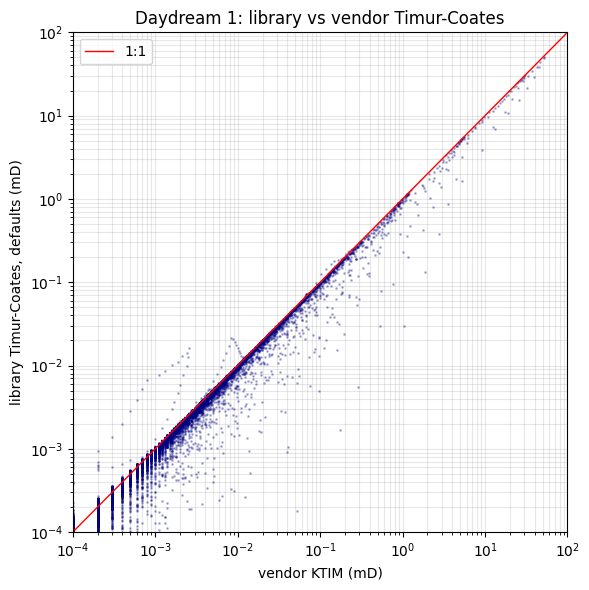

In [6]:
kc = nmr.permeability_coates(prefer_stored=False)      # library, defaults
ktim = nmr.stored_permeability["KTIM"]                 # vendor, downhole

both = np.isfinite(kc) & np.isfinite(ktim) & (kc > 0) & (ktim > 0)
resid = np.log10(kc[both]) - np.log10(ktim[both])
print("comparable samples      : %d" % both.sum())
print("median k, library/vendor: %.4f / %.4f mD" % (np.median(kc[both]), np.median(ktim[both])))
print("log10(lib/vendor)       : mean %+.3f, std %.3f decades" % (resid.mean(), resid.std()))

# Recover the vendor constant by calibrating the model to KTIM itself.
cal = nmr.calibrate_coates(nmr.depth[both], ktim[both])
print()
print("calibrate_coates vs KTIM ->", cal)

fig, ax = plt.subplots(figsize=(6, 6))
ax.loglog(ktim[both], kc[both], ".", ms=2, alpha=0.25, color="navy")
lims = (1e-4, 1e2)
ax.plot(lims, lims, "r-", lw=1, label="1:1")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("vendor KTIM (mD)")
ax.set_ylabel("library Timur-Coates, defaults (mD)")
ax.set_title("Daydream 1: library vs vendor Timur-Coates")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

### Reading the validation

The fit recovers $C = 9.6$ against the textbook default of 10, with
$R^2_{log} = 0.96$ - the library and the vendor implement the same model with
essentially the same constants. The remaining ~0.18-decade scatter is largest
below 0.001 mD, where the LAS's four-decimal export quantises `KTIM` (step
0.0001 mD), with some contribution from rounding of the exported porosities.

Two honest caveats. First, this validates the **implementation**, not the
permeability: both curves come from the same empirical model on the same
inputs. Absolute accuracy still requires calibration to core
(`calibrate_coates` with real plug permeabilities, exactly as used here but
with core data). Second, `KSDR` cannot be reproduced the same way - it needs
T2lm from the bins this export does not carry - which is precisely why bin
data are worth requesting from the vendor.

## 5. Export all derived results

`NMRData.to_dataframe()` bundles the inputs and every derivable curve
(Timur-Coates, Swirr, the vendor curves, all extras) into one table for QC or
hand-off. Bin-dependent columns are simply absent when bins are - the export
never invents data.

In [7]:
out = nmr.to_dataframe()
print("exported columns:", list(out.columns))
out.head()

exported columns: ['DEPTH', 'MPHI', 'MFFI', 'MBVI', 'T2CUTOFF', 'CMRP_3MS', 'CMR_TEMP', 'CDF', 'STIT', 'TENS', 'HD1_PPC1', 'HD2_PPC1', 'BS', 'GR_EDTC', 'KSDR', 'KTIM', 'KSDR_LAS', 'KTIM_LAS', 'K_SDR', 'K_COATES', 'SWIRR']


,DEPTH,MPHI,MFFI,MBVI,T2CUTOFF,CMRP_3MS,CMR_TEMP,CDF,STIT,TENS,...,HD2_PPC1,BS,GR_EDTC,KSDR,KTIM,KSDR_LAS,KTIM_LAS,K_SDR,K_COATES,SWIRR
0,4145.125,0.59,0.0,0.59,33.0,0.16,118.7033,-171.9887,0.0035,3490.1969,...,4.1703,8.5,79.2677,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,4145.100,0.59,0.0,0.59,33.0,0.16,118.7033,-168.3570,0.0374,3530.5512,...,4.1703,8.5,79.2677,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,4145.075,0.59,0.0,0.59,33.0,0.16,118.7033,-164.7253,0.0713,3570.9055,...,4.1703,8.5,79.2677,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,4145.050,0.59,0.0,0.59,33.0,0.16,118.7033,-161.0936,0.1051,3611.2598,...,4.1703,8.5,79.2677,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,4145.025,0.59,0.0,0.59,33.0,0.16,118.7033,-157.4619,0.1390,3651.6142,...,4.1703,8.5,79.2677,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## Pitfalls & parameter choices

- **`prefer_stored=True` is the default.** With vendor curves loaded,
  `permeability_coates()` / `permeability_sdr()` return the *stored* `KTIM` /
  `KSDR`. Pass `prefer_stored=False` when you mean "compute it yourself" -
  otherwise a comparison against the vendor compares the curve to itself.
- **Porosity units.** The container works in **pu**; `from_las` converts
  fractional (v/v) CMR curves automatically. Only worry about units when
  calling the standalone `sdr_permeability` / `coates_permeability` functions.
- **SDR needs T2lm.** No bins and no `T2LM` curve means no SDR - the method
  raises instead of guessing. Request bin exports (`T2B01...`) if you need it.
- **The cutoff is data, not folklore.** Here 33 ms comes from the file's
  `T2CUTOFF` curve (the clastic default; carbonates run ~92 ms). With only
  summary curves you also *cannot* re-split at another cutoff - `CMFF` was
  computed downhole at 33 ms.
- **Validating against `KTIM` is not core calibration.** It checks the
  implementation and constants; absolute permeability still needs plugs.
- **QC spikes before believing them.** High TCMR here is coal and washout,
  flagged by low GR and caliper-over-bit respectively.
- **This LAS is written deepest-first.** The reader warns about decreasing
  depth; per-sample math is safe, but thickness-style calculations elsewhere
  assume increasing depth.

## Recap

- A real CMR summary deliverable (Daydream 1) loads in one call:
  `NMRData.from_las(..., mphi_mnemonic="TCMR", mffi_mnemonic="CMFF")` -
  aliases, pu conversion, `MBVI = MPHI - MFFI`, cutoff, and vendor curves all
  handled.
- The porosity partition says **tight coal measures**: median 6.6 pu total,
  ~0.5 pu free fluid, median Swirr ~0.92; TCMR spikes are coal (low GR) and
  washout (caliper), not pay.
- Library **Timur-Coates matches the vendor's KTIM** with $R^2_{log} = 0.96$,
  and `calibrate_coates` recovers $C = 9.6$ vs the textbook 10.
- **T2-bin products (T2 distribution, T2lm, SDR, pore size) need bin data**;
  the API refuses cleanly when they are absent, and the vendor's downhole
  `KSDR` shows what those bins would buy.

## Try it yourself

> **Exercise 1.** Load the shallow section
> (`petrophys.sample("daydream1_cmr_shallow")`, 2860-3050 m) the same way and
> compare its Swirr and `KTIM` distributions against the deep section. Which
> section has more free fluid?
>
> **Exercise 2.** Re-run `calibrate_coates` with `fit_exponents=True`. Do the
> exponents move away from $(a, b) = (4, 2)$, and what does that say about the
> parameterisation the vendor used?
>
> **Exercise 3.** `TCMR - CMRP_3MS` isolates the porosity relaxing faster than
> 3 ms (micro/clay-bound signal; both curves are in `extra_curves` in v/v).
> Plot it against `GR_EDTC` - does micro-porosity track shaliness?

## What's next

Continue with **15 - Capillary Pressure & Saturation-Height**, where the
bound/free-fluid ideas from NMR reappear as capillary equilibrium above the
free-water level, and we predict water saturation from porosity, permeability
and height.